# LightGBM  Optimizacion Bayesiana

#### 2.1  Seteo del ambiente en Google Colab

Conectar la virtual machine donde esta corriendo Google Colab con el  Google Drive, para poder tener persistencia de archivos

In [ ]:
# # primero establecer el Runtime de Python 3
# from google.colab import drive
# drive.mount('/content/.drive')

Mounted at /content/.drive


In [1]:
# %%shell

# mkdir -p "/content/.drive/My Drive/dmeyf"
# mkdir -p "/content/buckets"
# ln -sfn  "/content/.drive/My Drive/dmeyf" /content/buckets/b1


# mkdir -p /content/buckets/b1/exp
# mkdir -p /content/buckets/b1/datasets
# mkdir -p /content/datasets


# # defino funcion descargar()
# descargar() {
#   carpeta_destino="/content/buckets/b1/datasets/"
#   url_origen="https://storage.googleapis.com/open-courses/dmeyf2026-9c6f/"
#   archivo="$1"

#   if ! test -f "$carpeta_destino""$archivo"; then
#     wget  "$url_origen""$archivo"  -O "$carpeta_destino""$archivo"
#   fi

#   if ! test -f  "/content/datasets/""$archivo"; then
#     cp  "$carpeta_destino""$archivo"  "/content/datasets/""$archivo"
#   fi;
# }


# # hago la descarga efectiva, llamando a descargar()
# descargar  "competencia_01_crudo.csv"


ERROR: Error in parse(text = input): <text>:1:1: unexpected SPECIAL
1: %%
    ^


## Generacion de la clase_ternaria

Esta parte se debe correr con el runtime en lenguaje **R** Ir al menu, Runtime -> Change Runtime Tipe -> Runtime type -> R

In [1]:
require( "data.table" )

# leo el dataset
dataset <- fread("/content/buckets/b1/datasets/competencia_01_crudo.csv.gz" )

# calculo el periodo0 consecutivo
dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes/100)*12 +  foto_mes%%100 ) ]


# ordeno
setorder( dsimple, numero_de_cliente, periodo0 )

# calculo topes
periodo_ultimo <- dsimple[, max(periodo0) ]
periodo_anteultimo <- periodo_ultimo - 1


# calculo los leads de orden 1 y 2
dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n=1:2, fill=NA, type="lead"),  numero_de_cliente ]

# assign most common class values = "CONTINUA"
dsimple[ periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA" ]

# calculo BAJA+1
dsimple[ periodo0 < periodo_ultimo &
    ( is.na(periodo1) | periodo0 + 1 < periodo1 ),
    clase_ternaria := "BAJA+1" ]

# calculo BAJA+2
dsimple[ periodo0 < periodo_anteultimo & (periodo0+1 == periodo1 )
    & ( is.na(periodo2) | periodo0 + 2 < periodo2 ),
    clase_ternaria := "BAJA+2" ]


# pego el resultado en el dataset original y grabo
setorder( dsimple, pos )
dataset[, clase_ternaria := dsimple$clase_ternaria ]

fwrite( dataset,
    file =  "/content/datasets/competencia_01.csv.gz",
    sep = ","
)

Loading required package: data.table


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%




In [2]:
setorder( dataset, foto_mes, clase_ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


### 2.2.2 Generación de nuevas columnas

In [3]:
head(dataset)

numero_de_cliente,foto_mes,active_quarter,cliente_vip,internet,cliente_edad,cliente_antiguedad,mrentabilidad,mrentabilidad_annual,mcomisiones,⋯,Visa_fultimo_cierre,Visa_mpagado,Visa_mpagospesos,Visa_mpagosdolares,Visa_fechaalta,Visa_mconsumototal,Visa_cconsumos,Visa_cadelantosefectivo,Visa_mpagominimo,clase_ternaria
<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>
12218654,202103,1,0,0,55,375,91.07,5334.66,99.49,⋯,7,0,NA,NA,8200,NA,NA,NA,0.00,BAJA+1
12450540,202103,1,0,0,49,50,2424.34,10363.94,2448.66,⋯,7,0,-13162.02,0,1499,9165.82,2,0,1994.10,BAJA+1
12472451,202103,1,0,2,60,375,4517.65,34123.81,2745.25,⋯,7,0,-27565.50,0,3976,11714.21,3,0,28398.33,BAJA+1
12539787,202103,1,0,0,41,197,1678.42,5207.46,1046.86,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,BAJA+1
12583358,202103,0,0,0,53,322,48.86,5466.39,0.00,⋯,7,0,NA,NA,4704,NA,NA,NA,0.00,BAJA+1
12646587,202103,0,0,0,82,322,1888.51,17845.98,1412.09,⋯,21,0,NA,NA,9288,NA,NA,NA,0.00,BAJA+1


In [4]:
colnames(dataset)

[1] "numero_de_cliente"                   
  [2] "foto_mes"                            
  [3] "active_quarter"                      
  [4] "cliente_vip"                         
  [5] "internet"                            
  [6] "cliente_edad"                        
  [7] "cliente_antiguedad"                  
  [8] "mrentabilidad"                       
  [9] "mrentabilidad_annual"                
 [10] "mcomisiones"                         
 [11] "mactivos_margen"                     
 [12] "mpasivos_margen"                     
 [13] "cproductos"                          
 [14] "tcuentas"                            
 [15] "ccuenta_corriente"                   
 [16] "mcuenta_corriente_adicional"         
 [17] "mcuenta_corriente"                   
 [18] "ccaja_ahorro"                        
 [19] "mcaja_ahorro"                        
 [20] "mcaja_ahorro_adicional"              
 [21] "mcaja_ahorro_dolares"                
 [22] "cdescubierto_preacordado"            
 [23] "mcuentas_saldo"                      
 [24] "ctarjeta_debito"                     
 [25] "ctarjeta_debito_transacciones"       
 [26] "mautoservicio"                       
 [27] "ctarjeta_visa"                       
 [28] "ctarjeta_visa_transacciones"         
 [29] "mtarjeta_visa_consumo"               
 [30] "ctarjeta_master"                     
 [31] "ctarjeta_master_transacciones"       
 [32] "mtarjeta_master_consumo"             
 [33] "cprestamos_personales"               
 [34] "mprestamos_personales"               
 [35] "cprestamos_prendarios"               
 [36] "mprestamos_prendarios"               
 [37] "cprestamos_hipotecarios"             
 [38] "mprestamos_hipotecarios"             
 [39] "cplazo_fijo"                         
 [40] "mplazo_fijo_dolares"                 
 [41] "mplazo_fijo_pesos"                   
 [42] "cinversion1"                         
 [43] "minversion1_pesos"                   
 [44] "minversion1_dolares"                 
 [45] "cinversion2"                         
 [46] "minversion2"                         
 [47] "cseguro_vida"                        
 [48] "cseguro_auto"                        
 [49] "cseguro_vivienda"                    
 [50] "cseguro_accidentes_personales"       
 [51] "ccaja_seguridad"                     
 [52] "cpayroll_trx"                        
 [53] "mpayroll"                            
 [54] "mpayroll2"                           
 [55] "cpayroll2_trx"                       
 [56] "ccuenta_debitos_automaticos"         
 [57] "mcuenta_debitos_automaticos"         
 [58] "ctarjeta_visa_debitos_automaticos"   
 [59] "mttarjeta_visa_debitos_automaticos"  
 [60] "ctarjeta_master_debitos_automaticos" 
 [61] "mttarjeta_master_debitos_automaticos"
 [62] "cpagodeservicios"                    
 [63] "mpagodeservicios"                    
 [64] "cpagomiscuentas"                     
 [65] "mpagomiscuentas"                     
 [66] "ccajeros_propios_descuentos"         
 [67] "mcajeros_propios_descuentos"         
 [68] "ctarjeta_visa_descuentos"            
 [69] "mtarjeta_visa_descuentos"            
 [70] "ctarjeta_master_descuentos"          
 [71] "mtarjeta_master_descuentos"          
 [72] "ccomisiones_mantenimiento"           
 [73] "mcomisiones_mantenimiento"           
 [74] "ccomisiones_otras"                   
 [75] "mcomisiones_otras"                   
 [76] "cforex"                              
 [77] "cforex_buy"                          
 [78] "mforex_buy"                          
 [79] "cforex_sell"                         
 [80] "mforex_sell"                         
 [81] "ctransferencias_recibidas"           
 [82] "mtransferencias_recibidas"           
 [83] "ctransferencias_emitidas"            
 [84] "mtransferencias_emitidas"            
 [85] "cextraccion_autoservicio"            
 [86] "mextraccion_autoservicio"            
 [87] "ccheques_depositados"                
 [88] "mcheques_depositados"                
 [89] "ccheques_emitidos"                 

In [5]:
dataset[, .N, by = foto_mes]

foto_mes,N
<int>,<int>
202103,162900
202104,163284
202105,163768
202106,164114
202107,164348
202108,164647


In [6]:
str(dataset)

Classes ‘data.table’ and 'data.frame':	983061 obs. of  155 variables:
 $ numero_de_cliente                   : num  12218654 12450540 12472451 12539787 12583358 ...
 $ foto_mes                            : int  202103 202103 202103 202103 202103 202103 202103 202103 202103 202103 ...
 $ active_quarter                      : int  1 1 1 1 0 0 0 1 1 1 ...
 $ cliente_vip                         : int  0 0 0 0 0 0 0 0 0 0 ...
 $ internet                            : int  0 0 2 0 0 0 0 0 0 0 ...
 $ cliente_edad                        : int  55 49 60 41 53 82 72 43 64 57 ...
 $ cliente_antiguedad                  : int  375 50 375 197 322 322 262 124 269 291 ...
 $ mrentabilidad                       : num  91.1 2424.3 4517.6 1678.4 48.9 ...
 $ mrentabilidad_annual                : num  5335 10364 34124 5207 5466 ...
 $ mcomisiones                         : num  99.5 2448.7 2745.2 1046.9 0 ...
 $ mactivos_margen                     : num  0 -132.2 1334.4 37.5 0 ...
 $ mpasivos_margen         

Creo los LAG DE ORDEN 1 Y 2

In [7]:

#library(data.table)

# 1. Trabajamos con una copia y guardamos el orden original
base <- copy(dataset)
base[, fila_original := .I]

# 2. Convertimos foto_mes a un índice mensual consecutivo
base[, periodo_idx := (foto_mes %/% 100) * 12 + foto_mes %% 100]

# 3. Identificamos las columnas que queremos desplazar
columnas <- setdiff(
  names(dataset),
  c("numero_de_cliente", "foto_mes","clase_ternaria")
)

# 4. Creamos las variables lag1
lag1 <- base[, c("numero_de_cliente", "periodo_idx", columnas),
             with = FALSE]

setnames(lag1, columnas, paste0(columnas, "_lag1"))
lag1[, periodo_idx := periodo_idx + 1L]

# 5. Creamos las variables lag2
lag2 <- base[, c("numero_de_cliente", "periodo_idx", columnas),
             with = FALSE]

setnames(lag2, columnas, paste0(columnas, "_lag2"))
lag2[, periodo_idx := periodo_idx + 2L]

# 6. Unimos los valores históricos con el dataset original
resultado <- merge(
  base, lag1,
  by = c("numero_de_cliente", "periodo_idx"),
  all.x = TRUE, sort = FALSE
)

resultado <- merge(
  resultado, lag2,
  by = c("numero_de_cliente", "periodo_idx"),
  all.x = TRUE, sort = FALSE
)

# 7. Recuperamos el orden original
setorder(resultado, fila_original)

# 8. Quitamos las columnas auxiliares
resultado[, c("fila_original", "periodo_idx") := NULL]

# 9. Ordeno las columnas

# Excluir columnas que no queremos desplazar
columnas <- setdiff(
  names(dataset),
  c("numero_de_cliente", "foto_mes", "clase_ternaria")
)

# Orden intercalado: original, lag1, lag2
orden_columnas <- c(
  "numero_de_cliente",
  "foto_mes",
  unlist(lapply(columnas, function(col) {
    c(col, paste0(col, "_lag1"), paste0(col, "_lag2"))
  })),
  "clase_ternaria"
)

# Aplicar el orden
resultado <- resultado[, ..orden_columnas]

# 9. Actualizamos el dataset
dataset <- resultado

In [8]:
dim(dataset)

[1] 983061    459

In [9]:
dataset[order(numero_de_cliente, foto_mes)][1:20]

numero_de_cliente,foto_mes,active_quarter,active_quarter_lag1,active_quarter_lag2,cliente_vip,cliente_vip_lag1,cliente_vip_lag2,internet,internet_lag1,⋯,Visa_cconsumos,Visa_cconsumos_lag1,Visa_cconsumos_lag2,Visa_cadelantosefectivo,Visa_cadelantosefectivo_lag1,Visa_cadelantosefectivo_lag2,Visa_mpagominimo,Visa_mpagominimo_lag1,Visa_mpagominimo_lag2,clase_ternaria
<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>
12159854,202103,1,NA,NA,0,NA,NA,0,NA,⋯,1,NA,NA,0,NA,NA,1137.81,NA,NA,CONTINUA
12159854,202104,1,1,NA,0,0,NA,0,0,⋯,1,1,NA,0,0,NA,1137.81,1137.81,NA,CONTINUA
12159854,202105,1,1,1,0,0,0,0,0,⋯,1,1,1,0,0,0,1137.81,1137.81,1137.81,CONTINUA
12159854,202106,1,1,1,0,0,0,0,0,⋯,1,1,1,0,0,0,1137.81,1137.81,1137.81,CONTINUA
12159854,202107,1,1,1,0,0,0,0,0,⋯,1,1,1,0,0,0,1137.81,1137.81,1137.81,NA
12159854,202108,1,1,1,0,0,0,0,0,⋯,1,1,1,0,0,0,1137.81,1137.81,1137.81,NA
12159858,202103,1,NA,NA,0,NA,NA,0,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,CONTINUA
12159858,202104,1,1,NA,0,0,NA,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,CONTINUA
12159858,202105,1,1,1,0,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,CONTINUA


Creo los DELTA LAG de orden 1 y 2

In [10]:

# 1. Identificar las variables originales (excluyendo IDs, clase y lags)
columnas <- setdiff(
  names(dataset),
  c("numero_de_cliente", "foto_mes", "clase_ternaria")
)

columnas <- columnas[!grepl("_(lag1|lag2|delta1|delta2)$", columnas)]

# 2. Crear delta1 y delta2
for (col in columnas) {
  dataset[, paste0(col, "_delta1") :=
            get(col) - get(paste0(col, "_lag1"))]

  dataset[, paste0(col, "_delta2") :=
            get(col) - get(paste0(col, "_lag2"))]
}

# 3. Ordenar las columnas
orden_columnas <- c(
  "numero_de_cliente",
  "foto_mes",
  unlist(lapply(columnas, function(col) {
    c(
      col,
      paste0(col, "_lag1"),
      paste0(col, "_lag2"),
      paste0(col, "_delta1"),
      paste0(col, "_delta2")
    )
  })),
  "clase_ternaria"
)

# 4. Aplicar el orden
dataset <- dataset[, ..orden_columnas]

# 5. Verificar el resultado
head(dataset[, 1:12, with = FALSE])

numero_de_cliente,foto_mes,active_quarter,active_quarter_lag1,active_quarter_lag2,active_quarter_delta1,active_quarter_delta2,cliente_vip,cliente_vip_lag1,cliente_vip_lag2,cliente_vip_delta1,cliente_vip_delta2
<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
12218654,202103,1,NA,NA,NA,NA,0,NA,NA,NA,NA
12450540,202103,1,NA,NA,NA,NA,0,NA,NA,NA,NA
12472451,202103,1,NA,NA,NA,NA,0,NA,NA,NA,NA
12539787,202103,1,NA,NA,NA,NA,0,NA,NA,NA,NA
12583358,202103,0,NA,NA,NA,NA,0,NA,NA,NA,NA
12646587,202103,0,NA,NA,NA,NA,0,NA,NA,NA,NA


In [11]:
dataset[order(numero_de_cliente, foto_mes)][1:20]

numero_de_cliente,foto_mes,active_quarter,active_quarter_lag1,active_quarter_lag2,active_quarter_delta1,active_quarter_delta2,cliente_vip,cliente_vip_lag1,cliente_vip_lag2,⋯,Visa_cadelantosefectivo_lag1,Visa_cadelantosefectivo_lag2,Visa_cadelantosefectivo_delta1,Visa_cadelantosefectivo_delta2,Visa_mpagominimo,Visa_mpagominimo_lag1,Visa_mpagominimo_lag2,Visa_mpagominimo_delta1,Visa_mpagominimo_delta2,clase_ternaria
<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
12159854,202103,1,NA,NA,NA,NA,0,NA,NA,⋯,NA,NA,NA,NA,1137.81,NA,NA,NA,NA,CONTINUA
12159854,202104,1,1,NA,0,NA,0,0,NA,⋯,0,NA,0,NA,1137.81,1137.81,NA,0.00,NA,CONTINUA
12159854,202105,1,1,1,0,0,0,0,0,⋯,0,0,0,0,1137.81,1137.81,1137.81,0.00,0.00,CONTINUA
12159854,202106,1,1,1,0,0,0,0,0,⋯,0,0,0,0,1137.81,1137.81,1137.81,0.00,0.00,CONTINUA
12159854,202107,1,1,1,0,0,0,0,0,⋯,0,0,0,0,1137.81,1137.81,1137.81,0.00,0.00,NA
12159854,202108,1,1,1,0,0,0,0,0,⋯,0,0,0,0,1137.81,1137.81,1137.81,0.00,0.00,NA
12159858,202103,1,NA,NA,NA,NA,0,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,CONTINUA
12159858,202104,1,1,NA,0,NA,0,0,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,CONTINUA
12159858,202105,1,1,1,0,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,CONTINUA


In [12]:
# Reemplazo los 0 que están mal por NA en 202105 del campo ccajas_depositos

dataset[foto_mes == 202105, ccajas_depositos := NA_real_]

In [13]:
# z_ctarjetas suma la cantidad de tarjetas de crédito visa y master

dataset[, z_ctarjetas :=
  fifelse(
    is.na(ctarjeta_visa) & is.na(ctarjeta_master),
    NA_real_,
    fifelse(is.na(ctarjeta_visa), 0, ctarjeta_visa) +
    fifelse(is.na(ctarjeta_master), 0, ctarjeta_master)
  )
]


# z_ctarjetas_transacciones suma la cantidad de transcacciones de las tarjetas de crédito visa y master
dataset[, z_ctarjetas_transacciones :=
  fifelse(
    is.na(ctarjeta_visa_transacciones) & is.na(ctarjeta_master_transacciones),
    NA_real_,
    fifelse(is.na(ctarjeta_visa_transacciones), 0, ctarjeta_visa_transacciones) +
    fifelse(is.na(ctarjeta_master_transacciones), 0, ctarjeta_master_transacciones)
  )
]


# z_mtarjetas_consumo suma llos montos de consumo de las tarjetas visa y master
dataset[, z_mtarjetas_consumo :=
  fifelse(
    is.na(mtarjeta_visa_consumo) & is.na(mtarjeta_master_consumo),
    NA_real_,
    fifelse(is.na(mtarjeta_visa_consumo), 0, mtarjeta_visa_consumo) +
    fifelse(is.na(mtarjeta_master_consumo), 0, mtarjeta_master_consumo)
  )
]

Calculo los RANKINGS de todas las variables

In [14]:

# 1. Identificar todas las variables a transformar
excluir <- c("numero_de_cliente", "foto_mes", "clase_ternaria")
columnas <- setdiff(names(dataset), excluir)

# 2. Ranking por mes, manteniendo el cero
for (col in columnas) {

  # Convertir la columna a double ANTES de modificarla
  set(dataset, j = col, value = as.numeric(dataset[[col]]))

  dataset[, (col) := {
    x <- get(col)
    resultado <- rep(NA_real_, .N)

    # Ceros
    resultado[!is.na(x) & x == 0] <- 0

    # Positivos: de 0 a 1
    pos <- which(!is.na(x) & x > 0)
    if (length(pos) > 0) {
      r <- frank(x[pos], ties.method = "dense")
      resultado[pos] <- r / max(r)
    }

    # Negativos: de -1 a 0
    neg <- which(!is.na(x) & x < 0)
    if (length(neg) > 0) {
      r <- frank(x[neg], ties.method = "dense")
      resultado[neg] <- (r - max(r) - 1) / max(r)
    }

    resultado
  }, by = foto_mes]
}

# 3. Comprobar el resultado
head(dataset[, .(
  foto_mes,
  Master_Finiciomora,
  Master_Finiciomora_lag1,
  Master_Finiciomora_lag2,
  Master_Finiciomora_delta1,
  Master_Finiciomora_delta2
)])

foto_mes,Master_Finiciomora,Master_Finiciomora_lag1,Master_Finiciomora_lag2,Master_Finiciomora_delta1,Master_Finiciomora_delta2
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
202103,NA,NA,NA,NA,NA
202103,NA,NA,NA,NA,NA
202103,NA,NA,NA,NA,NA
202103,NA,NA,NA,NA,NA
202103,NA,NA,NA,NA,NA
202103,NA,NA,NA,NA,NA


In [15]:
dataset[sample(.N, 20)]

numero_de_cliente,foto_mes,active_quarter,active_quarter_lag1,active_quarter_lag2,active_quarter_delta1,active_quarter_delta2,cliente_vip,cliente_vip_lag1,cliente_vip_lag2,⋯,Visa_cadelantosefectivo_delta2,Visa_mpagominimo,Visa_mpagominimo_lag1,Visa_mpagominimo_lag2,Visa_mpagominimo_delta1,Visa_mpagominimo_delta2,clase_ternaria,z_ctarjetas,z_ctarjetas_transacciones,z_mtarjetas_consumo
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
57147094,202104,1,1,NA,0,NA,0,0,NA,⋯,NA,0.107074236,0.099477269,NA,-0.001545595,NA,CONTINUA,0.5,0.000000000,0.000000000
13063924,202104,1,1,NA,0,NA,0,0,NA,⋯,NA,0.012925764,0.000000000,NA,0.107631786,NA,CONTINUA,0.5,0.027272727,0.174568043
60637714,202105,1,1,1,0,0,0,0,0,⋯,0,0.000000000,0.002623754,0.0000000000,-0.023668639,0.000000000,CONTINUA,0.5,0.009852217,0.027526649
16606309,202105,1,1,1,0,0,0,0,0,⋯,0,0.174668029,0.149029211,0.3617189978,0.213777067,-0.609921082,CONTINUA,0.5,0.256157635,0.970565492
25886093,202104,1,1,NA,0,NA,0,0,NA,⋯,NA,0.355633188,0.304926342,NA,0.174665618,NA,CONTINUA,0.5,0.118181818,0.958281024
27499602,202107,1,1,1,0,0,0,0,0,⋯,0,0.028169014,0.018375242,0.0130584192,0.087365388,0.115324877,NA,0.5,0.037558685,0.499349070
50907979,202108,1,1,1,0,0,0,0,0,⋯,0,0.001381215,0.001148671,0.0009688358,0.001329610,0.001124859,NA,0.5,0.004672897,0.005749258
21251252,202104,1,1,NA,0,NA,0,0,NA,⋯,NA,0.351615721,0.395057817,NA,-0.359093251,NA,CONTINUA,0.5,0.177272727,0.952374041
40020785,202108,1,1,1,0,0,0,0,0,⋯,0,0.101289134,0.070397112,0.0766994994,0.249434916,0.190601175,NA,0.5,0.112149533,0.692650080


In [16]:
dataset[numero_de_cliente == 63791172][order(foto_mes)]

numero_de_cliente,foto_mes,active_quarter,active_quarter_lag1,active_quarter_lag2,active_quarter_delta1,active_quarter_delta2,cliente_vip,cliente_vip_lag1,cliente_vip_lag2,⋯,Visa_cadelantosefectivo_delta2,Visa_mpagominimo,Visa_mpagominimo_lag1,Visa_mpagominimo_lag2,Visa_mpagominimo_delta1,Visa_mpagominimo_delta2,clase_ternaria,z_ctarjetas,z_ctarjetas_transacciones,z_mtarjetas_consumo
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
63791172,202103,1,NA,NA,NA,NA,0,NA,NA,⋯,NA,0.025782980,NA,NA,NA,NA,CONTINUA,0.5,0.08571429,0.3269085
63791172,202104,1,1,NA,0,NA,0,0,NA,⋯,NA,0.036681223,0.025819737,NA,0.0931550,NA,CONTINUA,0.5,0.08636364,0.4957947
63791172,202105,1,1,1,0,0,0,0,0,⋯,0,0.048859380,0.036732552,0.025848398,0.1094318,0.16470755,CONTINUA,0.5,0.14778325,0.5609612
63791172,202106,1,1,1,0,0,0,0,0,⋯,0,0.002574417,0.049219688,0.036809816,-0.3338219,-0.25037988,CONTINUA,0.5,0.09691630,0.4970978
63791172,202107,1,1,1,0,0,0,0,0,⋯,0,0.044873895,0.002578981,0.049312715,0.2986501,-0.03171704,NA,0.5,0.07042254,0.3707511
63791172,202108,1,1,1,0,0,0,0,0,⋯,0,0.056015961,0.044962258,0.002583562,0.1224571,0.30471191,NA,0.5,0.09813084,0.4461524


## 2.2 Optimizacion Hiperparámetros

Esta parte se debe correr con el runtime en lenguaje R Ir al menu, Runtime -> Change Runtime Type -> Runtime type -> R

### 2.2.1 Inicio

limpio el ambiente de R

In [17]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 17:37:29 2026"

### 2.2.2 Carga de Librerias

Esta parte lleva  demasiados   minutos la primera vez en Google Colab
<br> por suerte a partir del 15-septiembre empezaremos a trabajar con Google Cloud, en donde todas las librerias, de Python R y Julia ya estarán instaladas

In [18]:
# # instalo paquetes
# install.packages( c("R.utils", "rlist" ) )

In [19]:
# # Librerias  modernas  para la Bayesian Optimization
# install.packages( c("bbotk", "mlr3", "mlr3mbo", "mlr3learners", "DiceKriging") )

In [20]:
# # el LightGBM
# install.packages(c("lightgbm"))

In [21]:
library(data.table)
library(R.utils)
library(rlist)
library(bbotk)
library(mlr3)
library(mlr3mbo)
library(mlr3learners)
# library(paradox)
library(DiceKriging)
library(lightgbm)

Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


Attaching package: ‘R.utils’


The following object is masked from ‘package:utils’:

    timestamp


The following objects are masked from ‘package:base’:

    cat, commandArgs, getOption, isOpen, nullfile, parse, use, warnings


Loading required package: paradox


Attaching package: ‘mlr3’


The following object is masked from ‘package:R.utils’:

    resample


Loading required package:

### 2.2.3 Definicion de Parametros

aqui debe cargar SU semilla primigenia
<br>recuerde cambiar el numero de experimento en cada corrida nueva

In [3]:
PARAM <- list()
PARAM$experimento <- "HT4950-04"
PARAM$semilla_primigenia <-  775777


In [23]:
# training y future
PARAM$training_pct <- 70
PARAM$train <- c(202103,202104)
PARAM$validate <- c(202106)
PARAM$train_final <- c(202103,202104,202105,202106)
PARAM$future <- c(202108)
PARAM$cortes <- seq(9000, 15000, by= 500)

In [24]:
# # un undersampling de 0.1  toma solo el 10% de los CONTINUA
# # undersampling de 1.0  implica tomar TODOS los datos

# PARAM$trainingstrategy$undersampling <- 1

In [25]:
PARAM$hyperparametertuning$iteraciones <- 10 # iteraciones bayesianas

In [26]:
# Parametros LightGBM

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <-  list(
  boosting= "gbdt", # puede ir  dart  , ni pruebe random_forest
  objective= "binary",
  metric= "average_precision",
  feature_pre_filter= FALSE,
  first_metric_only= FALSE,
  boost_from_average= TRUE,
  force_row_wise= TRUE,
  deterministic= TRUE,
  verbosity= -100,

  seed= PARAM$semilla_primigenia,

  max_depth= -1L,
  min_gain_to_split= 0,
  lambda_l1= 0.0,
  lambda_l2= 0.0,
  max_bin= 31L,

  bagging_fraction= 1.0,
  pos_bagging_fraction= 1.0,
  neg_bagging_fraction= 1.0,
  is_unbalance= FALSE,
  scale_pos_weight= 1.0,

  drop_rate= 0.1,
  max_drop= 50,
  skip_drop= 0.5,

  extra_trees= FALSE,

  early_stopping= 0,
  min_data_in_leaf= 0,     # fijo, esto es FUNDAMENTAL
  feature_fraction= 0.50,  # fijo
  learning_rate= 0.005,    # fijo

  feature_fraction_bynode = 0.20, # lo agregué yo
  

  num_iterations= 20000,     # se modificara
  num_leaves= 1024,          # se modificara
  min_sum_hessian_in_leaf= 1e-06  # se modificara
)


Aqui se definen los hiperparámetros de LightGBM que participan de la Bayesian Optimization

In [27]:
# Aqui se cargan los bordes de los hiperparametros de la BO
#  es vital entender que se optimiza min_sum_hessian_in_leaf y que  min_data_in_leaf se deja fijo en CERO
# Instalar si todavía no está instalado
if (!requireNamespace("paradox", quietly = TRUE)) {
  install.packages("paradox")
}

# Cargar el paquete
library(paradox)

PARAM$hypeparametertuning$hs <- ps(
  num_iterations= p_int(lower= 64L,  upper= 4096L),
  num_leaves= p_int(lower= 16L,  upper= 2048L),
  min_sum_hessian_in_leaf= p_dbl( lower=1e-06, upper=0.1)
)

In [28]:
# logueo al archivo BO_log.txt
loguear  <- function( preg, arch=NA, verbose=TRUE )
{
  t0 <- Sys.time()
  reg <- copy( preg )
  if( "feature_contri" %in%  names(reg) ) {
    reg$feature_contri <- reg$feature_contri[1]
  }
  archivo <- arch
  if( is.na(arch) ) archivo <- paste0( folder, substitute( reg), ext )


  if( !file.exists( archivo ) )
  {
    # Escribo los titulos
    linea  <- paste0( "fecha\t",
                      paste( list.names(reg), collapse="\t" ), "\n" )

    cat( linea, file=archivo )
  }

  # escribo el registro
  linea  <- paste0( format(t0, "%Y%m%d.%H%M%S"),  "\t",     # la fecha y hora
                    gsub( ", ", "\t", toString( reg ) ),  "\n" )

  cat( linea, file=archivo, append=TRUE )  # grabo al archivo

  if( verbose )  cat( linea )   # imprimo por pantalla
}

### 2.2.4  Preprocesamiento

In [29]:
# carpeta de trabajo

setwd("/content/buckets/b1/exp")
dir.create(PARAM$experimento, showWarnings=FALSE)
setwd( paste0("/content/buckets/b1/exp/", PARAM$experimento))

In [30]:
dataset_bo <- dataset[
  foto_mes %in% c(PARAM$train, PARAM$validate)
]

# Variable objetivo binaria
dataset_bo[, clase01 :=
  as.integer(clase_ternaria %in% c("BAJA+1", "BAJA+2"))
]

# Selección de registros:
# training = 1 para marzo y abril
# training = 0 para junio
dataset_bo[, training :=
  as.integer(foto_mes %in% PARAM$train)
]

In [31]:
# Variables predictoras
campos_buenos <- setdiff(
  names(dataset_bo),
  c("numero_de_cliente","clase_ternaria","clase01","fold","azar","training"  )
)

#### 2.2.4.1  Salsa Magica (dedicada a Laura Pasquini)

Los EDAs que estan haciendo los alumnos de los lunes son pura falopa, y de la mala. El uso de Agentes de la IA solo les empera el daño cerebral, generan pedf larguisimos, que no te dan ganas de leerlos, carentes de insights y alma.
<br>El unico EDA que tiene realmente sentido, en este caso, es comparar la distribución de cada variable del mes donde se entrena 202104 y el mes donde se va a aplicar el modelo 202106, buscando Data Drifting.
<br>Aun con los reales datos del futuro, donde no se tiene la clase, SIEMPRE se puede analizar el Data Drifting.
<br>Para las variables con distribuciones distintas se puede hacer:
* Transformar la variable para hacerla homogenea entre los dos periodos
* Eliminarla (es lo simple, que se eligió hacer en este caso)

En esa exploracion gráfica del Data Drifting, se vio que estas variables cambian de distribucion entre 202104 y 202106, y se decidió brutalmente eliminarlas
* cprestamos_personales
* mprestamos_personales


más adelantes, se utilizarán técnicas más inclusivas, y se preservaran dichas variables, transformadas.


In [32]:
campos_buenos <- setdiff(
  campos_buenos,
  c(
    "cprestamos_personales",
    "cprestamos_personales_lag1",
    "cprestamos_personales_lag2",
    "cprestamos_personales_delta1",
    "cprestamos_personales_delta2",
    "mprestamos_personales",
    "mprestamos_personales_lag1",
    "mprestamos_personales_lag2",
    "mprestamos_personales_delta1",
    "mprestamos_personales_delta2"
  )
)

2.2.5 Configuracion Bayesian Optimization

In [33]:
giter <- 0

if( file.exists("BO_log.txt") ){
  tb_BO <- fread("BO_log.txt")
  giter <- tb_BO[, max(iter)]
}


In [34]:
# En el argumento x llegan los parametros de la bayesiana

Estimar_lightgbm <- function(xs) {

  flush.console()
  giter <<- giter + 1

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, xs)
  xx <- copy(param_completo)

  # entreno LightGBM
  modelo <- lgb.train(
    data= dtrain,
    valids= list( "val"=dvalidate),
    param= param_completo
  )


  # obtengo la ganancia
  xx$iter <- giter
  xx$metrica <- modelo$best_score

  loguear( xx, "BO_log.txt")
  set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")  # le reordeno a mlr3MBO

  return( list( metrica = xx$metrica) )
}

In [35]:
# Dataset de entrenamiento: marzo y abril en el formato que necesita LightGBM
dtrain <- lgb.Dataset(
  data = data.matrix(
    dataset_bo[training == 1L, campos_buenos, with = FALSE]
  ),
  label = dataset_bo[training == 1L, clase01],
  free_raw_data = FALSE
)

# Dataset de validación: junio en el formato que necesita LightGBM
dvalidate <- lgb.Dataset(
  data = data.matrix(
    dataset_bo[foto_mes == PARAM$validate, campos_buenos, with = FALSE]
  ),
  label = dataset_bo[foto_mes == PARAM$validate, clase01],
  free_raw_data = FALSE
)

In [36]:
# Comprobar dimensiones
nrow(dtrain)
ncol(dtrain)

nrow(dvalidate)
ncol(dvalidate)

[1] 326184

[1] 754

[1] 164114

[1] 754

In [30]:
dataset_bo[, .N, by = foto_mes][order(foto_mes)]

foto_mes,N
<int>,<int>
202103,162900
202104,163284
202106,164114


In [31]:
dataset_bo[, .(
  filas = .N,
  positivos = sum(clase01 == 1L, na.rm = TRUE)
), by = foto_mes][order(foto_mes)]

foto_mes,filas,positivos
<int>,<int>,<int>
202103,162900,1979
202104,163284,2103
202106,164114,1972


In [32]:
nrow(dtrain)
nrow(dvalidate)

[1] 326184

[1] 164114

In [33]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- Estimar_lightgbm # la funcion que voy a maximizar

objective <- ObjectiveRFun$new(
  fun= funcion_optimizar,
  domain= PARAM$hypeparametertuning$hs,
  codomain= ps(metrica = p_dbl(tags="maximize")),
  id= "BO_lightgbm"
)


instance <- OptimInstanceBatchSingleCrit$new(
  objective= objective,
  terminator=  trm("evals", n_evals = PARAM$hyperparametertuning$iteraciones)
)


surrogate <- srlrn(lrn("regr.km",
  optim.method = "BFGS",
  nugget.estim = TRUE,
  control= list(trace = FALSE)))

acq_function  <- acqf("ei")                 # expected improvement

acq_optimizer  <- acqo(
  optimizer  = opt("random_search", batch_size= 1000),
  terminator = trm("evals", n_evals= 1000)
)

optimizer <- opt("mbo",
  loop_function = bayesopt_ego,
  surrogate= surrogate,
  acq_function= acq_function,
  acq_optimizer= acq_optimizer
)



2.2.6 Corrida Bayesian Optimization

In [34]:
bayesiana_salida <- optimizer$optimize(instance)

INFO  [06:20:16.421] [bbotk] Starting to optimize 3 parameter(s) with '<OptimizerMbo>' and '<TerminatorEvals> [n_evals=10, k=0]'
INFO  [06:20:16.492] [bbotk] Evaluating 12 configuration(s)
20261011.062338	gbdt	binary	average_precision	FALSE	FALSE	TRUE	TRUE	TRUE	-100	775777	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.005	0.2	1744	97	0.00120496078325831	1	0.188296578357734
20261011.063840	gbdt	binary	average_precision	FALSE	FALSE	TRUE	TRUE	TRUE	-100	775777	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.005	0.2	2134	723	0.0499683059673722	2	0.175271487477328
20261011.064315	gbdt	binary	average_precision	FALSE	FALSE	TRUE	TRUE	TRUE	-100	775777	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.005	0.2	1501	375	0.0832677101841108	3	0.180280787982633
20261011.065901	gbdt	binary	average_precision	FALSE	FALSE	TRUE	TRUE	TRUE	-100	775777	-1	0	0	0	31	1	1	1	FALSE	1	0.1	50	0.5	FALSE	0	0	0.5	0.005	0.2	3655	1444	0.0470121287355432	4	0.175964870818132
20261011.070737	gbdt	binary	averag

In [35]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 07:45:37 2026"

Luego de este punto, en la carpeta del experimento quedó el archivo BO_log.txt que posee todas las iteraciones de la Bayesian Optimization

### Valido con el calculo de ganancia

In [38]:
# setwd("/content/buckets/b1/exp")
# dir.create(PARAM$experimento, showWarnings= FALSE)
# setwd( paste0("/content/buckets/b1/exp/", PARAM$experimento ))

In [39]:
 # # cergo los mejores hiperparametros, que son los de mayor metrica
 # tb_bayesiana <- fread("BO_log.txt")
 # setorder( tb_bayesiana, -metrica )
 # PARAM$out$lgbm$mejores_hiperparametros <- as.list(tb_bayesiana[1])

In [40]:
# param_final <- modifyList(
#     PARAM$lgbm$param_fijos,
#     PARAM$out$lgbm$mejores_hiperparametros
#   )

In [41]:
  # # entreno LightGBM
  # modelo <- lgb.train(
  #   data= dtrain,
  #   valids= list( "val"=dvalidate),
  #   param= param_final
  # )

In [51]:
# # Dataset de junio
# tb_prediccion <- copy(
#   dataset_bo[
#     foto_mes == PARAM$validate,
#     c(
#       "numero_de_cliente",
#       "foto_mes",
#       "clase_ternaria",
#       campos_buenos
#     ),
#     with = FALSE
#   ]
# )

# # Predecir probabilidades
# prediccion_junio <- predict(
#   modelo,
#   data.matrix(
#     tb_prediccion[, campos_buenos, with = FALSE]
#   )
# )

# # Agregar probabilidades
# tb_prediccion[, prob := as.numeric(prediccion_junio)]

# # Verificar
# head(tb_prediccion[, .(
#   numero_de_cliente,
#   foto_mes,
#   clase_ternaria,
#   prob
# )])

numero_de_cliente,foto_mes,clase_ternaria,prob
<dbl>,<int>,<chr>,<dbl>
12245017,202106,BAJA+1,0.0005623379
12296757,202106,BAJA+1,0.0018449711
12343612,202106,BAJA+1,0.0583133357
12377842,202106,BAJA+1,0.0067640304
12392815,202106,BAJA+1,0.0101632302
12402952,202106,BAJA+1,0.0017881723


In [52]:
# # Asignar la ganancia real según la clase
# tb_prediccion[, gan := fifelse(
#   clase_ternaria == "BAJA+2",
#   1072500,
#   -27500
# )]

# # Ordenar de mayor a menor probabilidad
# setorder(tb_prediccion, -prob)

# # Calcular la ganancia acumulada
# tb_prediccion[, ganancia_acumulada := cumsum(gan)]
# tb_prediccion[, pos := seq_len(.N)]

# # Evaluar los cortes
# for (envios in PARAM$cortes) {
#   if (envios <= nrow(tb_prediccion)) {
#     ganancia <- tb_prediccion[envios, ganancia_acumulada]
#     cat(envios, "\t", ganancia, "\n")
#   }
# }

9000 	 458700000 
9500 	 466950000 
10000 	 470800000 
10500 	 472450000 
11000 	 476300000 
11500 	 471350000 
12000 	 471900000 
12500 	 470250000 
13000 	 465300000 
13500 	 461450000 
14000 	 456500000 
14500 	 448250000 
15000 	 444400000 


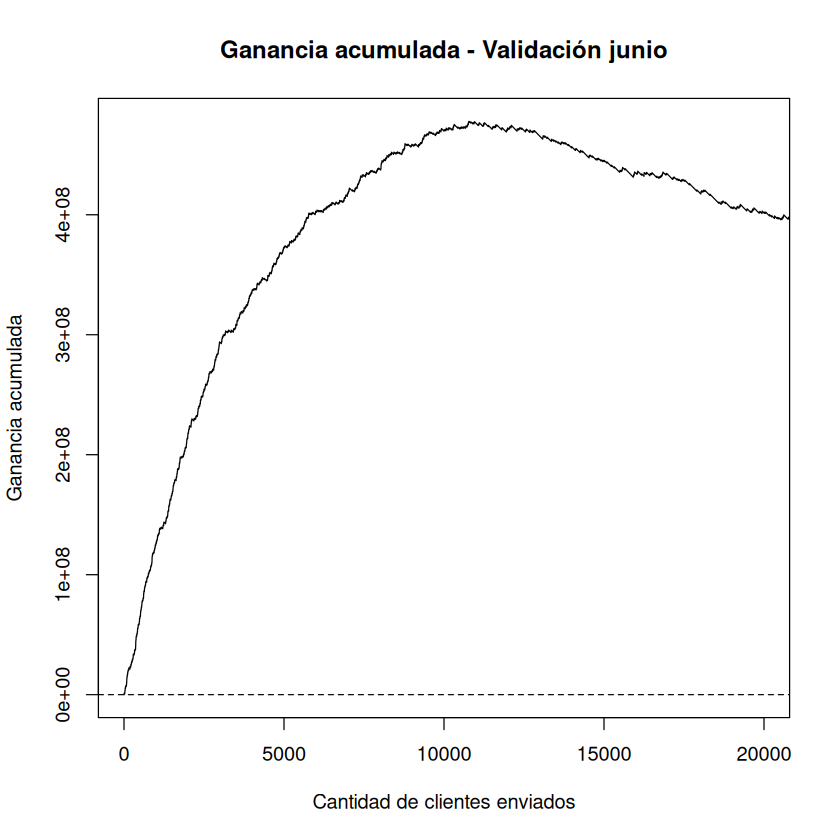

In [55]:
# plot(
#   tb_prediccion$pos,
#   tb_prediccion$ganancia_acumulada,
#   type = "l",
#   xlim = c(0, 20000),
#   ylim = c(0, max(tb_prediccion$ganancia_acumulada, na.rm = TRUE)),
#   xlab = "Cantidad de clientes enviados",
#   ylab = "Ganancia acumulada",
#   main = "Ganancia acumulada - Validación junio"
# )

# abline(h = 0, lty = 2)

In [56]:
# # Buscar la máxima ganancia acumulada
# fila_max <- which.max(tb_prediccion$ganancia_acumulada)

# cat("Máxima ganancia:", tb_prediccion$ganancia_acumulada[fila_max], "\n")
# cat("Cantidad de envíos:", tb_prediccion$pos[fila_max], "\n")

Máxima ganancia: 477867500 
Cantidad de envíos: 10783 


In [57]:
# tb_prediccion[fila_max, .(
#   envios = pos,
#   ganancia_maxima = ganancia_acumulada
# )]

envios,ganancia_maxima
<int>,<dbl>
10783,477867500


## 2.3  Produccion

### Final Training
Construyo el modelo final, que es uno solo, no hace ningun tipo de particion < training, validation, testing>]

In [36]:
setwd("/content/buckets/b1/exp")
dir.create(PARAM$experimento, showWarnings= FALSE)
setwd( paste0("/content/buckets/b1/exp/", PARAM$experimento ))

In [37]:
 # cergo los mejores hiperparametros, que son los de mayor metrica
 tb_bayesiana <- fread("BO_log.txt")
 setorder( tb_bayesiana, -metrica )
 PARAM$out$lgbm$mejores_hiperparametros <- as.list(tb_bayesiana[1])

#### Final Training Dataset

Aqui esta la gran decision de en qué meses hago el Final Training
<br> debo utilizar los mejores hiperparámetros que encontré en la  optimización bayesiana

In [38]:
# clase01
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+1", "BAJA+2"), 1L, 0L)]

In [39]:
dataset_train <- dataset[foto_mes %in% PARAM$train_final]
dataset_train[,.N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


#### Final Training Hyperparameters

In [40]:
# aplico el modelo a los datos sin clase
dfuture <- dataset[foto_mes %in% PARAM$future]


In [41]:
campos_buenos <- unique(c(
  campos_buenos,
  "cprestamos_personales",
  "cprestamos_personales_lag1",
  "cprestamos_personales_lag2",
  "cprestamos_personales_delta1",
  "cprestamos_personales_delta2",
  "mprestamos_personales",
  "mprestamos_personales_lag1",
  "mprestamos_personales_lag2",
  "mprestamos_personales_delta1",
  "mprestamos_personales_delta2"
))

campos_buenos <- setdiff(campos_buenos, c("numero_de_cliente", "clase_ternaria", "clase01"))

In [42]:
# # Entreno el modelo sobre todo el periodo

# dtrain_final <- lgb.Dataset(
#   data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
#   label= dataset_train[, clase01]
# )

# modelo_final <- lgb.train(
#   data= dtrain_final,
#   param= param_final
# )

In [43]:
# # hago el predict en los datos del futuro, y calculo la ganancia

# # aplico el modelo a los datos nuevos
# prediccion <- predict(
#   modelo_final,
#   data.matrix(dfuture[, campos_buenos, with= FALSE])
# )



In [44]:
# Las semillas
semillas <- c(
  765461, 765487, 765497, 765503, 765521,
  384157, 414857, 503857, 697757, 735157,
  775777, 333331, 555557, 111119, 799999,
  600013, 620003, 640007, 660007, 680003
)

In [45]:
# Preparar los datos una sola vez
dtrain_final <- lgb.Dataset(
  data = data.matrix(
    dataset_train[, campos_buenos, with = FALSE]
  ),
  label = dataset_train[, clase01],
  free_raw_data = FALSE
)

# Tabla para guardar las predicciones de los 20 modelos
tb_predicciones <- dfuture[, .(numero_de_cliente, foto_mes)]

In [46]:
for (semilla in semillas) {

  cat(
    "\nEntrenando modelo con semilla:", semilla,
    "|", format(Sys.time(), "%H:%M:%S"), "\n"
  )
  flush.console()
  flush(stdout())

  # Hiperparámetros optimizados + semilla de esta corrida
  param_final <- modifyList(
    PARAM$lgbm$param_fijos,
    PARAM$out$lgbm$mejores_hiperparametros
  )

  param_final$seed <- semilla
  param_final$bagging_seed <- semilla
  param_final$feature_fraction_seed <- semilla
  param_final$drop_seed <- semilla
  param_final$data_random_seed <- semilla

  # Entrenar modelo
  modelo_final <- lgb.train(
    data = dtrain_final,
    param = param_final
  )

  # Guardar el modelo
  lgb.save(
    modelo_final,
    paste0("modelo_semilla_", semilla, ".txt")
  )

  # Predecir agosto
  prediccion <- predict(
    modelo_final,
    data.matrix(dfuture[, campos_buenos, with = FALSE])
  )

  # Guardar probabilidades de esta semilla
  nombre_columna <- paste0("prob_", semilla)
  tb_predicciones[, (nombre_columna) := as.numeric(prediccion)]

  cat(
    "FINALIZADO | Semilla:", semilla,
    "| Hora:", format(Sys.time(), "%H:%M:%S"), "\n"
  )
  flush.console()
  flush(stdout())

  rm(modelo_final, prediccion)
  gc()
}

# Guardar las predicciones en un solo archivo
fwrite(tb_predicciones, "predicciones_agosto_20_semillas.csv")

# Ver las primeras filas
head(tb_predicciones)


Entrenando modelo con semilla: 765461 | 07:45:45 
FINALIZADO | Semilla: 765461 | Hora: 07:54:15 

Entrenando modelo con semilla: 765487 | 07:54:16 
FINALIZADO | Semilla: 765487 | Hora: 08:02:53 

Entrenando modelo con semilla: 765497 | 08:02:54 
FINALIZADO | Semilla: 765497 | Hora: 08:11:29 

Entrenando modelo con semilla: 765503 | 08:11:29 
FINALIZADO | Semilla: 765503 | Hora: 08:20:03 

Entrenando modelo con semilla: 765521 | 08:20:03 
FINALIZADO | Semilla: 765521 | Hora: 08:28:39 

Entrenando modelo con semilla: 384157 | 08:28:40 
FINALIZADO | Semilla: 384157 | Hora: 08:37:21 

Entrenando modelo con semilla: 414857 | 08:37:21 
FINALIZADO | Semilla: 414857 | Hora: 08:46:02 

Entrenando modelo con semilla: 503857 | 08:46:03 
FINALIZADO | Semilla: 503857 | Hora: 08:54:34 

Entrenando modelo con semilla: 697757 | 08:54:35 
FINALIZADO | Semilla: 697757 | Hora: 09:03:20 

Entrenando modelo con semilla: 735157 | 09:03:20 
FINALIZADO | Semilla: 735157 | Hora: 09:11:47 

Entrenando modelo c

numero_de_cliente,foto_mes,prob_765461,prob_765487,prob_765497,prob_765503,prob_765521,prob_384157,prob_414857,prob_503857,⋯,prob_775777,prob_333331,prob_555557,prob_111119,prob_799999,prob_600013,prob_620003,prob_640007,prob_660007,prob_680003
<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12159854,202108,0.0015780132,0.0017000732,0.001467104,0.0015389292,0.0015010843,0.001360369,0.0014163791,0.001487682,⋯,0.001525521,0.001227186,0.0014861771,0.001321131,0.001565382,0.0016478277,0.001298937,0.001388217,0.001546823,0.0013801889
12159858,202108,0.0016236713,0.0018119876,0.001684527,0.0014967555,0.0016720947,0.001546009,0.0015650474,0.001648400,⋯,0.001511416,0.001468850,0.0016150238,0.001621011,0.001616124,0.0017292032,0.001602122,0.001792494,0.001457606,0.0016300469
12160484,202108,0.0022242270,0.0022681547,0.002068866,0.0022973837,0.0024501397,0.002058994,0.0020464199,0.002268552,⋯,0.002405678,0.002278714,0.0020105984,0.002319928,0.002235457,0.0021833736,0.002404579,0.002251343,0.002085893,0.0024244734
12160591,202108,0.0011998624,0.0012140148,0.001194397,0.0012397520,0.0011388349,0.001097967,0.0013004254,0.000999830,⋯,0.001110249,0.001132640,0.0010094574,0.001038817,0.001095911,0.0012688534,0.001241515,0.001373153,0.001232831,0.0011981507
12160747,202108,0.0045042922,0.0045691433,0.004305710,0.0043303771,0.0040865642,0.004812791,0.0043862686,0.003705132,⋯,0.004762227,0.003760072,0.0041425027,0.004436202,0.004396425,0.0045472291,0.004193434,0.004130164,0.004155548,0.0042628192
12160769,202108,0.0009718578,0.0009002555,0.001248170,0.0008702237,0.0009873692,0.000960489,0.0008884696,0.001083383,⋯,0.001048689,0.001013539,0.0009133878,0.000818994,0.001082512,0.0009336468,0.001024955,0.001073472,0.000893692,0.0009379497


In [48]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 10:37:59 2026"

#### Leo archivos y veo las mejores particiones

In [49]:
# # Nombre del experimento
# nombre_experimento <- PARAM$experimento

# # Leer las predicciones
# archivo_entrada <- "predicciones_agosto_20_semillas.csv"
# tb_predicciones <- fread(archivo_entrada)

# # Detectar las semillas disponibles
# columnas_prob <- grep("^prob_", names(tb_predicciones), value = TRUE)

# # Cortes: 9000, 9500, ..., 15000
# cortes <- seq(9000, 15000, by = 500)

# # Verificar que haya suficientes clientes
# stopifnot(nrow(tb_predicciones) >= max(cortes))

# # Convertir los números de cliente a texto sin notación científica
# clientes <- format(
#   tb_predicciones$numero_de_cliente,
#   scientific = FALSE,
#   trim = TRUE
# )

# # Generar los archivos para cada semilla y cada corte
# for (columna in columnas_prob) {

#   orden <- order(-tb_predicciones[[columna]], na.last = TRUE)
#   clientes_ordenados <- clientes[orden]

#   # Obtener el número de semilla
#   numero_semilla <- sub("^prob_", "", columna)

#   for (corte in cortes) {

#     seleccion <- clientes_ordenados[seq_len(corte)]

#     # Nombre variable según el experimento
#     nombre_archivo <- paste0(
#       nombre_experimento, "_",
#       numero_semilla, "_",
#       corte, ".csv"
#     )

#     fwrite(
#       data.table(seleccion),
#       file = nombre_archivo,
#       col.names = FALSE,
#       quote = FALSE,
#       sep = ","
#     )

#     cat("Generado:", nombre_archivo, "\n")
#   }
# }

# cat(
#   "\nProceso terminado. Total de archivos generados:",
#   length(columnas_prob) * length(cortes),
#   "\n"
# )

Generado: HT4950-04_765461_9000.csv 
Generado: HT4950-04_765461_9500.csv 
Generado: HT4950-04_765461_10000.csv 
Generado: HT4950-04_765461_10500.csv 
Generado: HT4950-04_765461_11000.csv 
Generado: HT4950-04_765461_11500.csv 
Generado: HT4950-04_765461_12000.csv 
Generado: HT4950-04_765461_12500.csv 
Generado: HT4950-04_765461_13000.csv 
Generado: HT4950-04_765461_13500.csv 
Generado: HT4950-04_765461_14000.csv 
Generado: HT4950-04_765461_14500.csv 
Generado: HT4950-04_765461_15000.csv 
Generado: HT4950-04_765487_9000.csv 
Generado: HT4950-04_765487_9500.csv 
Generado: HT4950-04_765487_10000.csv 
Generado: HT4950-04_765487_10500.csv 
Generado: HT4950-04_765487_11000.csv 
Generado: HT4950-04_765487_11500.csv 
Generado: HT4950-04_765487_12000.csv 
Generado: HT4950-04_765487_12500.csv 
Generado: HT4950-04_765487_13000.csv 
Generado: HT4950-04_765487_13500.csv 
Generado: HT4950-04_765487_14000.csv 
Generado: HT4950-04_765487_14500.csv 
Generado: HT4950-04_765487_15000.csv 
Generado: HT4950

zipeo los archivos y los guardo

In [50]:
# # Nombre del experimento
# nombre_experimento <- PARAM$experimento

# # Buscar los CSV correspondientes a este experimento
# archivos <- list.files(
#   path = ".",
#   pattern = paste0(
#     "^",
#     nombre_experimento,
#     "_[0-9]+_[0-9]+\\.csv$"
#   ),
#   full.names = TRUE
# )

# if (length(archivos) == 0) {
#   stop("No se encontraron archivos CSV para el experimento ", nombre_experimento)
# }

# # Nombre variable del ZIP
# archivo_zip <- paste0(
#   nombre_experimento,
#   "_listas_clientes.zip"
# )

# utils::zip(
#   zipfile = archivo_zip,
#   files = archivos,
#   flags = "-j"
# )

# cat(
#   "ZIP generado:", normalizePath(archivo_zip),
#   "\nCantidad de CSV incluidos:", length(archivos),
#   "\n"
# )

ZIP generado: /home/ds/buckets/b1/exp/HT4950-04/HT4950-04_listas_clientes.zip 
Cantidad de CSV incluidos: 260 


In [53]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 14:19:20 2026"

Genero ensambles con el promedio

In [63]:
# Nombre del experimento
nombre_experimento <- PARAM$experimento

# Leer las predicciones de las semillas
tb_predicciones <- fread("predicciones_agosto_20_semillas.csv")

# Detectar las columnas de probabilidades
columnas_prob <- grep("^prob_", names(tb_predicciones), value = TRUE)

# Verificar que existan probabilidades
stopifnot(length(columnas_prob) > 0)
stopifnot("numero_de_cliente" %in% names(tb_predicciones))

# Calcular el promedio de probabilidades por cliente
tb_predicciones[, prob_promedio := rowMeans(
  as.matrix(.SD),
  na.rm = TRUE
), .SDcols = columnas_prob]

# Ordenar de mayor a menor probabilidad promedio
setorder(tb_predicciones, -prob_promedio)

# Cortes: 9000, 9500, ..., 15000
cortes <- seq(9000, 15000, by = 500)

# Verificar que haya suficientes clientes
stopifnot(nrow(tb_predicciones) >= max(cortes))

# Convertir los números de cliente a texto sin notación científica
clientes_ordenados <- format(
  tb_predicciones$numero_de_cliente,
  scientific = FALSE,
  trim = TRUE
)

# Generar un CSV por cada corte
for (corte in cortes) {

  seleccion <- clientes_ordenados[seq_len(corte)]

  nombre_archivo <- paste0(
    nombre_experimento,
    "_promedio_",
    corte,
    ".csv"
  )

  fwrite(
    data.table(seleccion),
    file = nombre_archivo,
    col.names = FALSE,
    quote = FALSE,
    sep = ","
  )

  cat("Generado:", nombre_archivo, "\n")
}

# Guardar también todas las probabilidades promedio
fwrite(
  tb_predicciones,
  paste0(nombre_experimento, "_predicciones_promedio.csv")
)

cat("\nProceso terminado.\n")
cat("Semillas promediadas:", length(columnas_prob), "\n")
cat("Archivos de cortes generados:", length(cortes), "\n")

Generado: HT4950-04_promedio_9000.csv 
Generado: HT4950-04_promedio_9500.csv 
Generado: HT4950-04_promedio_10000.csv 
Generado: HT4950-04_promedio_10500.csv 
Generado: HT4950-04_promedio_11000.csv 
Generado: HT4950-04_promedio_11500.csv 
Generado: HT4950-04_promedio_12000.csv 
Generado: HT4950-04_promedio_12500.csv 
Generado: HT4950-04_promedio_13000.csv 
Generado: HT4950-04_promedio_13500.csv 
Generado: HT4950-04_promedio_14000.csv 
Generado: HT4950-04_promedio_14500.csv 
Generado: HT4950-04_promedio_15000.csv 

Proceso terminado.
Semillas promediadas: 20 
Archivos de cortes generados: 13 


In [64]:
# zipeo los ensambles

In [65]:

# nombre_experimento <- PARAM$experimento

# archivos <- list.files(
#   path = ".",
#   pattern = paste0(
#     "^",
#     nombre_experimento,
#     "_promedio_[0-9]+\\.csv$"
#   ),
#   full.names = TRUE
# )

# if (length(archivos) != 13) {
#   stop("Se esperaban 13 archivos de cortes, pero se encontraron ", length(archivos))
# }

# archivo_zip <- paste0(
#   nombre_experimento,
#   "_promedio_listas_clientes.zip"
# )

# utils::zip(
#   zipfile = archivo_zip,
#   files = archivos,
#   flags = "-j"
# )

# cat("ZIP generado:", normalizePath(archivo_zip), "\n")
# cat("CSV incluidos:", length(archivos), "\n")

ZIP generado: /home/ds/buckets/b1/exp/HT4950-04/HT4950-04_promedio_listas_clientes.zip 
CSV incluidos: 13 


In [2]:
#Guardo una copia de la notebook que generó los archivos

In [4]:
# 1. Nombre del experimento
nombre_experimento <- PARAM$experimento

# 2. Carpeta donde está la notebook original
carpeta_origen <- "/home/ds/buckets/b1/dmeyf2026/primera_competencia"

# 3. Buscar la notebook original
archivos_ipynb <- list.files(
  path = carpeta_origen,
  pattern = "\\.ipynb$",
  full.names = TRUE
)

if (length(archivos_ipynb) != 1) {
  stop(
    "Se esperaba una sola notebook en ",
    carpeta_origen,
    ", pero se encontraron ",
    length(archivos_ipynb),
    "."
  )
}

archivo_origen <- archivos_ipynb[1]

# 4. Carpeta de destino del experimento
carpeta_destino <- file.path(
  "/content/buckets/b1/exp",
  nombre_experimento
)

dir.create(
  carpeta_destino,
  recursive = TRUE,
  showWarnings = FALSE
)

# 5. Copiar la notebook con el nombre del experimento
archivo_destino <- file.path(
  carpeta_destino,
  paste0(nombre_experimento, ".ipynb")
)

if (file.copy(
  from = archivo_origen,
  to = archivo_destino,
  overwrite = TRUE
)) {
  cat("Notebook copiada correctamente.\n")
  cat("Original:", archivo_origen, "\n")
  cat("Destino:", archivo_destino, "\n")
} else {
  stop("No se pudo copiar la notebook.")
}

Notebook copiada correctamente.
Original: /home/ds/buckets/b1/dmeyf2026/primera_competencia/primera_compe_2.ipynb 
Destino: /content/buckets/b1/exp/HT4950-04/HT4950-04.ipynb 
